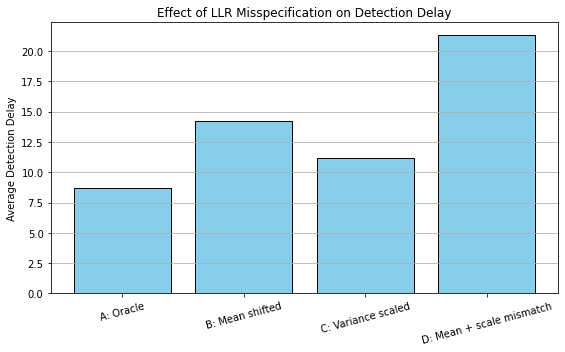

In [1]:
# Re-run after kernel reset
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import sys
sys.path.append('../scripts')
from OracleCUSUM import CUSUM

# Define mismatched LLR cases
def make_llr_pdfs(case, delta):
    if case == 'A':  # Oracle
        return lambda x: norm.pdf(x, 0, 1), lambda x: norm.pdf(x, delta, 1)
    elif case == 'B':  # Mean shifted
        return lambda x: norm.pdf(x, 0.2, 1), lambda x: norm.pdf(x, delta + 0.2, 1)
    elif case == 'C':  # Variance scaled
        return lambda x: norm.pdf(x, 0, 1.2), lambda x: norm.pdf(x, delta, 0.8)
    elif case == 'D':  # Mean + variance mismatch
        return lambda x: norm.pdf(x, 0.3, 1.1), lambda x: norm.pdf(x, delta + 0.3, 0.9)
    else:
        raise ValueError("Unknown mismatch case")

# Run detection delay experiment for each mismatch
def evaluate_mismatch_cases(delta=1.0, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    results = {}

    for case in ['A', 'B', 'C', 'D']:
        f0_m, f1_m = make_llr_pdfs(case, delta)
        detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)

        delays = []
        for _ in range(num_trials):
            stream = np.concatenate([
                np.random.normal(0, 1, changepoint),
                np.random.normal(delta, 1, stream_length - changepoint)
            ])
            _, _, tau = detector.run(stream)
            if tau is not None and tau > changepoint:
                delays.append(tau - changepoint)

        avg_delay = np.mean(delays) if delays else np.nan
        results[case] = avg_delay

    return results

# Run and display results
mismatch_results = evaluate_mismatch_cases()

# Plotting
cases = ['A', 'B', 'C', 'D']
delays = [mismatch_results[c] for c in cases]
labels = [
    'A: Oracle',
    'B: Mean shifted',
    'C: Variance scaled',
    'D: Mean + scale mismatch'
]

plt.figure(figsize=(8, 5))
plt.bar(cases, delays, tick_label=labels, color='skyblue', edgecolor='black')
plt.ylabel("Average Detection Delay")
plt.title("Effect of LLR Misspecification on Detection Delay")
plt.xticks(rotation=15)
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

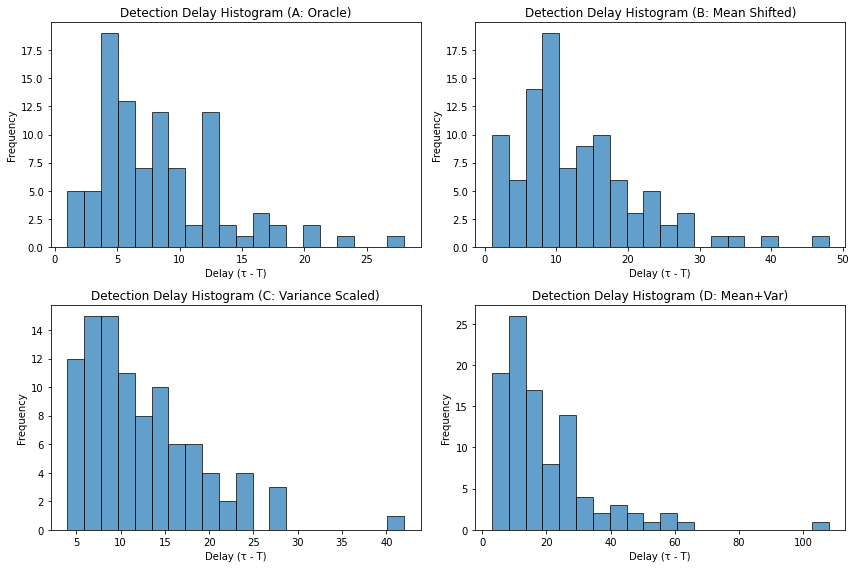

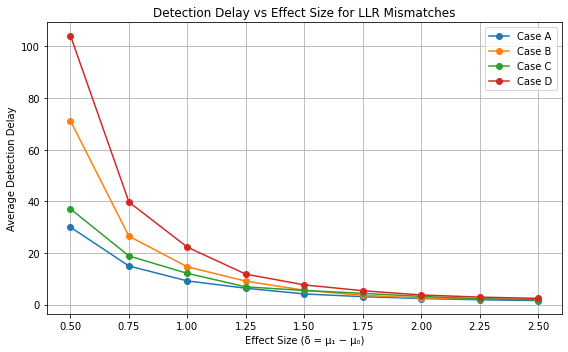

In [2]:
# 1. Detection delay histograms per mismatch case (fixed delta)
def delay_histograms(delta=1.0, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    all_delays = {}
    for case in ['A', 'B', 'C', 'D']:
        f0_m, f1_m = make_llr_pdfs(case, delta)
        detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)
        delays = []

        for _ in range(num_trials):
            stream = np.concatenate([
                np.random.normal(0, 1, changepoint),
                np.random.normal(delta, 1, stream_length - changepoint)
            ])
            _, _, tau = detector.run(stream)
            if tau is not None and tau > changepoint:
                delays.append(tau - changepoint)

        all_delays[case] = delays

    return all_delays

# 2. Delay vs delta for all cases
def delay_vs_delta(delta_vals, threshold=5.0, num_trials=100, stream_length=300, changepoint=50):
    delays_by_case = {c: [] for c in ['A', 'B', 'C', 'D']}

    for delta in delta_vals:
        for case in ['A', 'B', 'C', 'D']:
            f0_m, f1_m = make_llr_pdfs(case, delta)
            detector = CUSUM(f0_pdf=f0_m, f1_pdf=f1_m, threshold=threshold)
            delays = []

            for _ in range(num_trials):
                stream = np.concatenate([
                    np.random.normal(0, 1, changepoint),
                    np.random.normal(delta, 1, stream_length - changepoint)
                ])
                _, _, tau = detector.run(stream)
                if tau is not None and tau > changepoint:
                    delays.append(tau - changepoint)

            avg = np.mean(delays) if delays else np.nan
            delays_by_case[case].append(avg)

    return delays_by_case

# Run both experiments
delta_vals = np.linspace(0.5, 2.5, 9)
delay_vs_d = delay_vs_delta(delta_vals)
delay_hists = delay_histograms()

# Plot 1: Histograms
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs = axs.flatten()
labels = ['A: Oracle', 'B: Mean Shifted', 'C: Variance Scaled', 'D: Mean+Var']
for i, case in enumerate(['A', 'B', 'C', 'D']):
    axs[i].hist(delay_hists[case], bins=20, edgecolor='black', alpha=0.7)
    axs[i].set_title(f'Detection Delay Histogram ({labels[i]})')
    axs[i].set_xlabel("Delay (τ - T)")
    axs[i].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

# Plot 2: Delay vs Delta
plt.figure(figsize=(8, 5))
for case in ['A', 'B', 'C', 'D']:
    plt.plot(delta_vals, delay_vs_d[case], marker='o', label=f'Case {case}')
plt.xlabel("Effect Size (δ = μ₁ − μ₀)")
plt.ylabel("Average Detection Delay")
plt.title("Detection Delay vs Effect Size for LLR Mismatches")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
| Case  | Mismatch Type            | What Changed                                 | Observed Impact                            | Notes                                                                                |
| ----- | ------------------------ | -------------------------------------------- | ------------------------------------------ | ------------------------------------------------------------------------------------ |
| **A** | ✅ Oracle (No mismatch)  | None                                         | Fastest, consistent detection              | Baseline                                                                             |
| **B** | 🔸 Mean shift            | $\tilde{f}_0$, $\tilde{f}_1$ shifted by +0.2 | Moderate delay increase, still usable      | Log-likelihood ratios slightly biased; delay grows as change becomes less detectable |
| **C** | 🔴 Variance scaled       | Variance wrong (1.2 and 0.8)                 | Delay increases significantly              | LLR becomes too flat or steep → errors in evidence accumulation                      |
| **D** | 🔻 Mean + scale mismatch | Both mean and variance shifted               | Worst performance, high delay and variance | Multiple sources of misalignment compound the effect                                 |
